# Breast Cancer Classification
**CPCS433 - Artificial Intelligence Topics - Assignment #1**

Models used: Logistic Regression, Perceptron and Support Vector Machine (SVM).

The goal is to predict if a tumor is malignant (M) or benign (B) from the measurements of the cell nuclei.

Note: the file `breast-cancer.csv` must be in the same folder as this notebook (in Google Colab, upload it using the Files panel on the left).

In [1]:
# import the libraries we need
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression, Perceptron
from sklearn.svm import SVC
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, roc_auc_score, accuracy_score
from sklearn.decomposition import PCA

## Step 1: Load the dataset

In [2]:
# read the csv file from the same folder as the notebook
data = pd.read_csv("breast-cancer.csv")

# look at the size and the first rows
print("Shape of the data (rows, columns):", data.shape)
data.head()

Shape of the data (rows, columns): (569, 32)


,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [3]:
# look at the column types and some basic statistics
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 32 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       569 non-null    int64  
 1   diagnosis                569 non-null    str    
 2   radius_mean              569 non-null    float64
 3   texture_mean             569 non-null    float64
 4   perimeter_mean           569 non-null    float64
 5   area_mean                569 non-null    float64
 6   smoothness_mean          569 non-null    float64
 7   compactness_mean         569 non-null    float64
 8   concavity_mean           569 non-null    float64
 9   concave points_mean      569 non-null    float64
 10  symmetry_mean            569 non-null    float64
 11  fractal_dimension_mean   569 non-null    float64
 12  radius_se                569 non-null    float64
 13  texture_se               569 non-null    float64
 14  perimeter_se             569 non-null

diagnosis
B    357
M    212
Name: count, dtype: int64


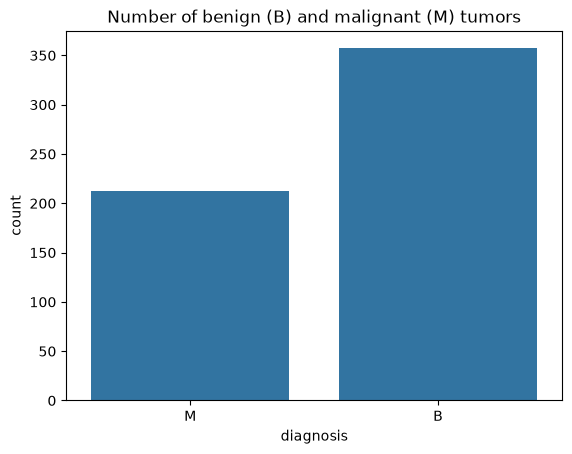

In [4]:
# how many malignant (M) and benign (B) tumors do we have?
print(data["diagnosis"].value_counts())

sns.countplot(x="diagnosis", data=data)
plt.title("Number of benign (B) and malignant (M) tumors")
plt.show()

## Step 2: Preprocessing
We check missing values, look at outliers, encode the diagnosis and then scale the features.

### 2.1 Drop the id column and check missing values

In [5]:
# the id column is just a number for each patient, it is not useful for predicting, so we drop it
data = data.drop("id", axis=1)

# count the missing values in each column
missing = data.isnull().sum()
print("Total missing values:", missing.sum())
print(missing[missing > 0])

Total missing values: 0
Series([], dtype: int64)


### 2.2 Check for outliers
We use the IQR rule: a value is an outlier if it is below Q1 - 1.5*IQR or above Q3 + 1.5*IQR.

In [6]:
# count the outliers in each feature using the IQR rule
feature_names = data.drop("diagnosis", axis=1).columns

outlier_counts = {}
for name in feature_names:
    q1 = data[name].quantile(0.25)
    q3 = data[name].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    count = ((data[name] < lower) | (data[name] > upper)).sum()
    outlier_counts[name] = count

outlier_table = pd.Series(outlier_counts).sort_values(ascending=False)
print("Features with the most outliers:")
print(outlier_table.head(10))
print()
print("Total number of outlier values:", outlier_table.sum(), "out of", data.shape[0] * len(feature_names), "values")

# how many rows have at least one outlier, and are they benign or malignant?
rows_with_outliers = []
for index, row in data[feature_names].iterrows():
    has_outlier = False
    for name in feature_names:
        q1 = data[name].quantile(0.25)
        q3 = data[name].quantile(0.75)
        iqr = q3 - q1
        if row[name] < q1 - 1.5 * iqr or row[name] > q3 + 1.5 * iqr:
            has_outlier = True
    rows_with_outliers.append(has_outlier)

print()
print("Rows with at least one outlier:", sum(rows_with_outliers), "out of", data.shape[0])
print(data[rows_with_outliers]["diagnosis"].value_counts())

Features with the most outliers:
area_se                    65
radius_se                  38
perimeter_se               38
area_worst                 35
smoothness_se              30
fractal_dimension_se       28
compactness_se             28
symmetry_se                27
area_mean                  25
fractal_dimension_worst    24
dtype: int64

Total number of outlier values: 608 out of 17070 values



Rows with at least one outlier: 171 out of 569
diagnosis
M    114
B     57
Name: count, dtype: int64


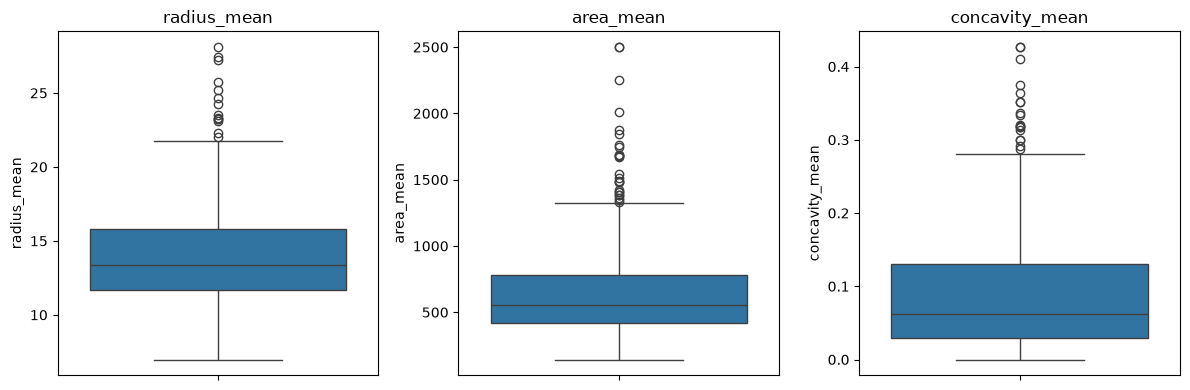

In [7]:
# boxplots of a few features to see the outliers
plt.figure(figsize=(12, 4))
for i, name in enumerate(["radius_mean", "area_mean", "concavity_mean"]):
    plt.subplot(1, 3, i + 1)
    sns.boxplot(y=data[name])
    plt.title(name)
plt.tight_layout()
plt.show()

**Decision about outliers:** only about 3.6% of the individual values are outliers (608 out of 17070). About two thirds of the rows that contain an outlier are malignant (M) tumors, so the outliers are mostly real very large or irregular tumors and not data mistakes. Removing them would delete many useful malignant cases from a small dataset, so we keep them. To reduce their effect we use `StandardScaler` so all features are on the same scale.

### 2.3 Encode the diagnosis (M = 1, B = 0)

In [8]:
# change the letters into numbers: M (malignant) = 1, B (benign) = 0
data["diagnosis"] = data["diagnosis"].map({"M": 1, "B": 0})

print(data["diagnosis"].value_counts())

diagnosis
0    357
1    212
Name: count, dtype: int64


In [9]:
# separate the features (X) and the target (y)
X = data.drop("diagnosis", axis=1)
y = data["diagnosis"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (569, 30)
y shape: (569,)


## Step 3: Train/test split (80/20) and scaling

In [10]:
# split the data 80% train and 20% test with random_state=42
# stratify=y keeps the same M/B ratio in the train and test sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training set:", X_train.shape)
print("Test set:", X_test.shape)

Training set: (455, 30)
Test set: (114, 30)


In [11]:
# I split first and then scale. The scaler is fitted only on the training data
# so the test data does not leak any information (mean and std) into training.
# The test data is only transformed with the numbers learned from the training data.
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# check: the scaled training features should have mean about 0 and std about 1
print("Mean of first 3 scaled train features:", X_train_scaled[:, :3].mean(axis=0).round(3))
print("Std of first 3 scaled train features:", X_train_scaled[:, :3].std(axis=0).round(3))

Mean of first 3 scaled train features: [-0.  0.  0.]
Std of first 3 scaled train features: [1. 1. 1.]


## Step 4: Train Logistic Regression and Perceptron

In [12]:
# Logistic Regression
log_model = LogisticRegression(random_state=42, max_iter=1000)
log_model.fit(X_train_scaled, y_train)

# Perceptron
perc_model = Perceptron(random_state=42)
perc_model.fit(X_train_scaled, y_train)

print("Logistic Regression train accuracy:", round(log_model.score(X_train_scaled, y_train), 4))
print("Perceptron train accuracy:", round(perc_model.score(X_train_scaled, y_train), 4))

Logistic Regression train accuracy: 0.9868
Perceptron train accuracy: 0.978


## Step 5: Train SVM with Grid Search
We try different values of `C` and different kernels and use 5-fold cross validation on the training set to pick the best one.

In [13]:
# the values we want to try for the SVM
param_grid = {
    "C": [0.1, 1, 10, 100],
    "kernel": ["linear", "rbf", "poly", "sigmoid"]
}

svm = SVC(random_state=42)
grid = GridSearchCV(svm, param_grid, cv=5, scoring="accuracy")
grid.fit(X_train_scaled, y_train)

print("Best parameters:", grid.best_params_)
print("Best cross-validation accuracy:", round(grid.best_score_, 4))

Best parameters: {'C': 1, 'kernel': 'rbf'}
Best cross-validation accuracy: 0.9758


In [14]:
# show all the grid search results in a table to compare the combinations
results = pd.DataFrame(grid.cv_results_)
results = results[["param_C", "param_kernel", "mean_test_score", "rank_test_score"]]
results.sort_values("rank_test_score").head(10)

,param_C,param_kernel,mean_test_score,rank_test_score
5,1.0,rbf,0.975824,1
9,10.0,rbf,0.973626,2
8,10.0,linear,0.969231,3
0,0.1,linear,0.969231,3
4,1.0,linear,0.962637,5
14,100.0,poly,0.962637,5
12,100.0,linear,0.958242,7
13,100.0,rbf,0.958242,8
7,1.0,sigmoid,0.953846,9
3,0.1,sigmoid,0.949451,10


In [15]:
# the best SVM (GridSearchCV already refit it on the whole training set)
svm_model = grid.best_estimator_
best_params = grid.best_params_

## Step 6: Evaluate the models on the test set

In [16]:
# predictions of each model on the test set
log_pred = log_model.predict(X_test_scaled)
perc_pred = perc_model.predict(X_test_scaled)
svm_pred = svm_model.predict(X_test_scaled)

class_names = ["Benign (0)", "Malignant (1)"]

print("===== Logistic Regression =====")
print(classification_report(y_test, log_pred, target_names=class_names))

print("===== Perceptron =====")
print(classification_report(y_test, perc_pred, target_names=class_names))

print("===== SVM (best parameters) =====")
print(classification_report(y_test, svm_pred, target_names=class_names))

===== Logistic Regression =====
               precision    recall  f1-score   support

   Benign (0)       0.96      0.99      0.97        72
Malignant (1)       0.97      0.93      0.95        42

     accuracy                           0.96       114
    macro avg       0.97      0.96      0.96       114
 weighted avg       0.97      0.96      0.96       114

===== Perceptron =====
               precision    recall  f1-score   support

   Benign (0)       0.97      0.99      0.98        72
Malignant (1)       0.98      0.95      0.96        42

     accuracy                           0.97       114
    macro avg       0.97      0.97      0.97       114
 weighted avg       0.97      0.97      0.97       114

===== SVM (best parameters) =====
               precision    recall  f1-score   support

   Benign (0)       0.96      1.00      0.98        72
Malignant (1)       1.00      0.93      0.96        42

     accuracy                           0.97       114
    macro avg       0.9

In [17]:
# put the test accuracy of the three models in one table
log_acc = accuracy_score(y_test, log_pred)
perc_acc = accuracy_score(y_test, perc_pred)
svm_acc = accuracy_score(y_test, svm_pred)

acc_table = pd.DataFrame({
    "Model": ["Logistic Regression", "Perceptron", "SVM"],
    "Test Accuracy": [log_acc, perc_acc, svm_acc]
})
acc_table

,Model,Test Accuracy
0,Logistic Regression,0.964912
1,Perceptron,0.973684
2,SVM,0.973684


## Step 7: Confusion matrices

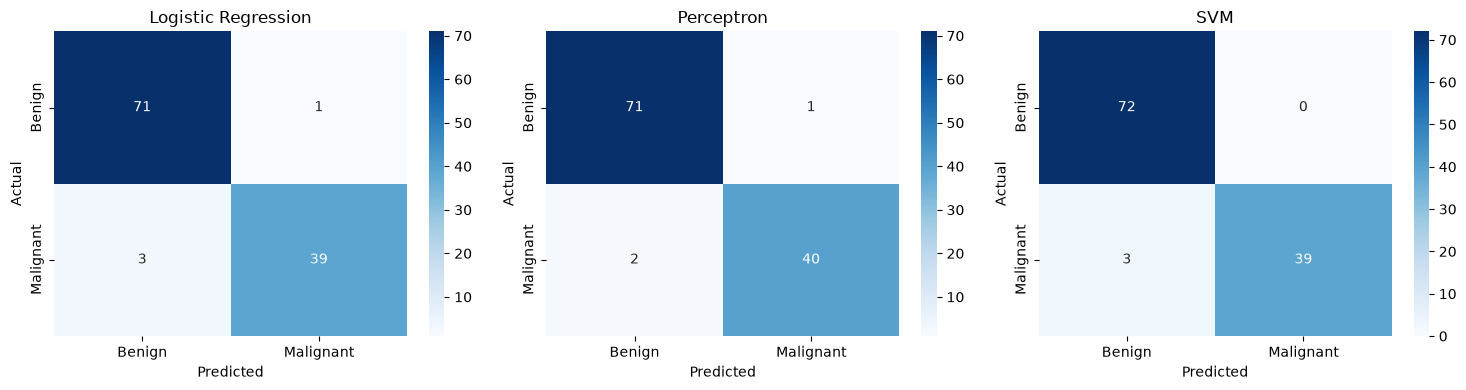

In [18]:
# confusion matrix of each model drawn as a seaborn heatmap
models_preds = [
    ("Logistic Regression", log_pred),
    ("Perceptron", perc_pred),
    ("SVM", svm_pred)
]

plt.figure(figsize=(15, 4))
for i, (name, pred) in enumerate(models_preds):
    cm = confusion_matrix(y_test, pred)
    plt.subplot(1, 3, i + 1)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=["Benign", "Malignant"],
                yticklabels=["Benign", "Malignant"])
    plt.title(name)
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
plt.tight_layout()
plt.show()

In [19]:
# print the numbers of the confusion matrices in words
for name, pred in models_preds:
    cm = confusion_matrix(y_test, pred)
    tn, fp, fn, tp = cm.ravel()
    print(name, "-> correct benign:", tn, "| benign predicted as malignant:", fp,
          "| malignant predicted as benign:", fn, "| correct malignant:", tp)

Logistic Regression -> correct benign: 71 | benign predicted as malignant: 1 | malignant predicted as benign: 3 | correct malignant: 39
Perceptron -> correct benign: 71 | benign predicted as malignant: 1 | malignant predicted as benign: 2 | correct malignant: 40
SVM -> correct benign: 72 | benign predicted as malignant: 0 | malignant predicted as benign: 3 | correct malignant: 39


## Step 8: ROC curves and AUC

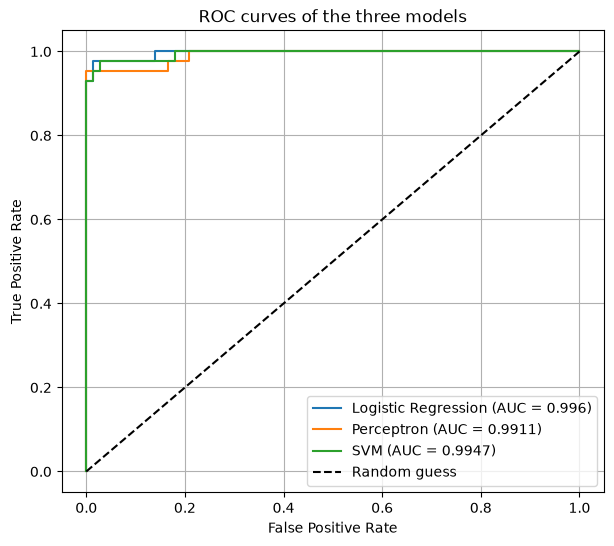

AUC Logistic Regression: 0.996
AUC Perceptron: 0.9911
AUC SVM: 0.9947


In [20]:
# scores for the ROC curve
# Logistic Regression can give probabilities, Perceptron and SVM use decision_function
log_scores = log_model.predict_proba(X_test_scaled)[:, 1]
perc_scores = perc_model.decision_function(X_test_scaled)
svm_scores = svm_model.decision_function(X_test_scaled)

# false positive rate, true positive rate and AUC for each model
fpr_log, tpr_log, _ = roc_curve(y_test, log_scores)
fpr_perc, tpr_perc, _ = roc_curve(y_test, perc_scores)
fpr_svm, tpr_svm, _ = roc_curve(y_test, svm_scores)

auc_log = roc_auc_score(y_test, log_scores)
auc_perc = roc_auc_score(y_test, perc_scores)
auc_svm = roc_auc_score(y_test, svm_scores)

# all three ROC curves on one graph
plt.figure(figsize=(7, 6))
plt.plot(fpr_log, tpr_log, label="Logistic Regression (AUC = " + str(round(auc_log, 4)) + ")")
plt.plot(fpr_perc, tpr_perc, label="Perceptron (AUC = " + str(round(auc_perc, 4)) + ")")
plt.plot(fpr_svm, tpr_svm, label="SVM (AUC = " + str(round(auc_svm, 4)) + ")")
plt.plot([0, 1], [0, 1], "k--", label="Random guess")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC curves of the three models")
plt.legend(loc="lower right")
plt.grid(True)
plt.show()

print("AUC Logistic Regression:", round(auc_log, 4))
print("AUC Perceptron:", round(auc_perc, 4))
print("AUC SVM:", round(auc_svm, 4))

## Step 9: Decision boundaries (2D with PCA)
The data has 30 features, so we cannot draw a boundary in 30 dimensions. For this visualization only, we reduce the data to 2 dimensions with PCA.

In [21]:
# PCA is used only for this visualization. It is fitted on the scaled training data only.
pca = PCA(n_components=2, random_state=42)
X_train_2d = pca.fit_transform(X_train_scaled)
X_test_2d = pca.transform(X_test_scaled)

print("Variance explained by the 2 components:", pca.explained_variance_ratio_.round(3))
print("Total variance explained:", round(pca.explained_variance_ratio_.sum(), 3))

Variance explained by the 2 components: [0.446 0.185]
Total variance explained: 0.631


In [22]:
# The models must be retrained on the 2D PCA data, because the earlier models
# were trained on 30 features and cannot predict on 2 features.
# The SVM uses the best parameters found by the grid search in Step 5.
log_2d = LogisticRegression(random_state=42, max_iter=1000)
log_2d.fit(X_train_2d, y_train)

perc_2d = Perceptron(random_state=42)
perc_2d.fit(X_train_2d, y_train)

svm_2d = SVC(C=best_params["C"], kernel=best_params["kernel"], random_state=42)
svm_2d.fit(X_train_2d, y_train)

print("2D test accuracy Logistic Regression:", round(log_2d.score(X_test_2d, y_test), 4))
print("2D test accuracy Perceptron:", round(perc_2d.score(X_test_2d, y_test), 4))
print("2D test accuracy SVM:", round(svm_2d.score(X_test_2d, y_test), 4))

2D test accuracy Logistic Regression: 0.9474
2D test accuracy Perceptron: 0.9825
2D test accuracy SVM: 0.9298


In [23]:
# function to draw the decision boundary of a model on the 2D data
def plot_boundary(model, X_2d, y, title):
    # make a grid of points that covers the whole plot area
    x_min = X_2d[:, 0].min() - 1
    x_max = X_2d[:, 0].max() + 1
    y_min = X_2d[:, 1].min() - 1
    y_max = X_2d[:, 1].max() + 1
    xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.05),
                         np.arange(y_min, y_max, 0.05))

    # predict the class of every point in the grid
    grid_points = np.c_[xx.ravel(), yy.ravel()]
    Z = model.predict(grid_points)
    Z = Z.reshape(xx.shape)

    # colored regions show the predicted class, the line between them is the boundary
    plt.contourf(xx, yy, Z, alpha=0.3, cmap="coolwarm")
    plt.contour(xx, yy, Z, colors="black", linewidths=1)

    # the real points, benign in blue and malignant in red
    plt.scatter(X_2d[y == 0, 0], X_2d[y == 0, 1], c="blue", edgecolor="k", s=20, label="Benign (0)")
    plt.scatter(X_2d[y == 1, 0], X_2d[y == 1, 1], c="red", edgecolor="k", s=20, label="Malignant (1)")
    plt.xlabel("PCA component 1")
    plt.ylabel("PCA component 2")
    plt.title(title)
    plt.legend()

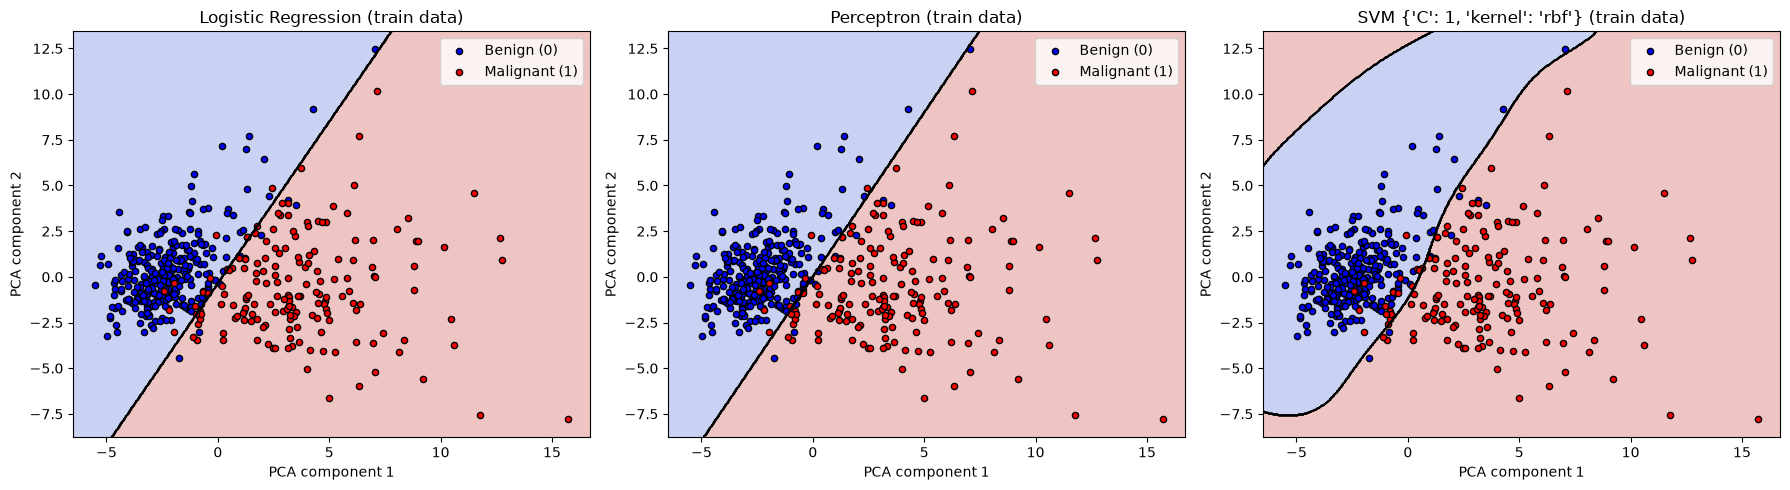

In [24]:
# decision boundaries with the training points
plt.figure(figsize=(18, 5))

plt.subplot(1, 3, 1)
plot_boundary(log_2d, X_train_2d, y_train, "Logistic Regression (train data)")

plt.subplot(1, 3, 2)
plot_boundary(perc_2d, X_train_2d, y_train, "Perceptron (train data)")

plt.subplot(1, 3, 3)
plot_boundary(svm_2d, X_train_2d, y_train, "SVM " + str(best_params) + " (train data)")

plt.tight_layout()
plt.show()

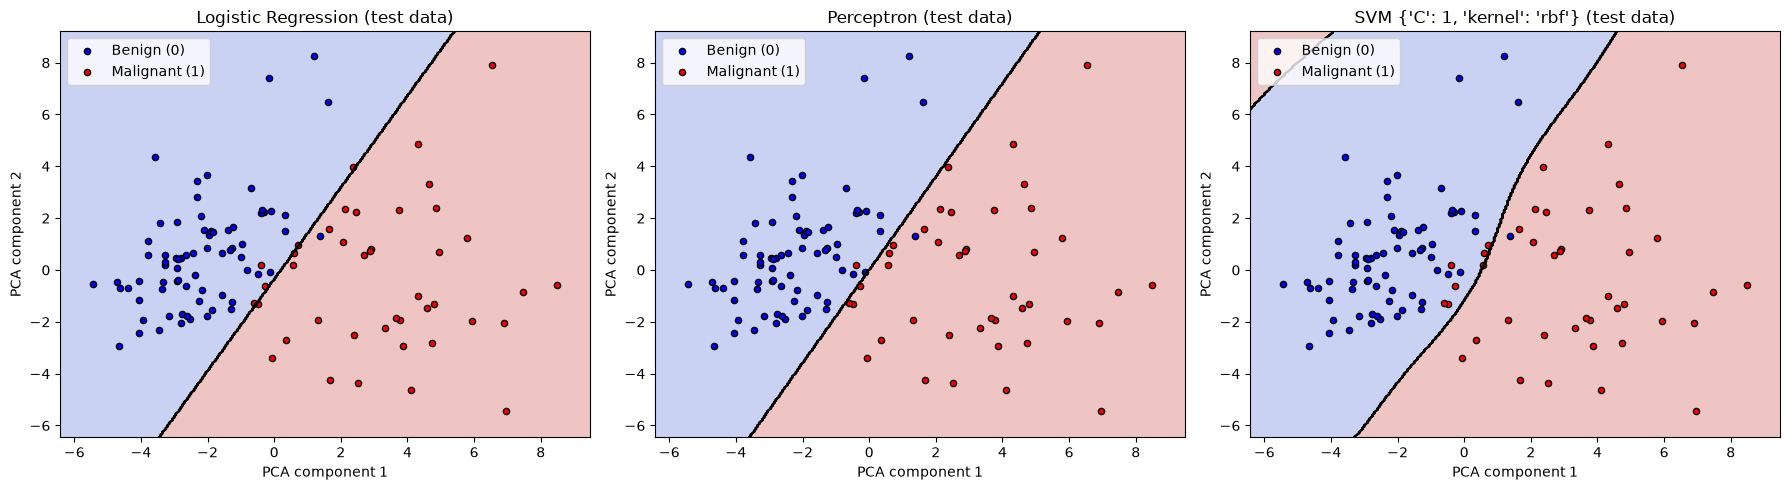

In [25]:
# the same boundaries but with the test points
plt.figure(figsize=(18, 5))

plt.subplot(1, 3, 1)
plot_boundary(log_2d, X_test_2d, y_test, "Logistic Regression (test data)")

plt.subplot(1, 3, 2)
plot_boundary(perc_2d, X_test_2d, y_test, "Perceptron (test data)")

plt.subplot(1, 3, 3)
plot_boundary(svm_2d, X_test_2d, y_test, "SVM " + str(best_params) + " (test data)")

plt.tight_layout()
plt.show()

In [26]:
# print the numbers used in the summary
print("Best SVM parameters:", best_params)
print()
summary = pd.DataFrame({
    "Model": ["Logistic Regression", "Perceptron", "SVM"],
    "Accuracy": [log_acc, perc_acc, svm_acc],
    "AUC": [auc_log, auc_perc, auc_svm],
    "2D PCA accuracy": [log_2d.score(X_test_2d, y_test),
                        perc_2d.score(X_test_2d, y_test),
                        svm_2d.score(X_test_2d, y_test)]
})
summary.round(4)

Best SVM parameters: {'C': 1, 'kernel': 'rbf'}



,Model,Accuracy,AUC,2D PCA accuracy
0,Logistic Regression,0.9649,0.9960,0.9474
1,Perceptron,0.9737,0.9911,0.9825
2,SVM,0.9737,0.9947,0.9298


## Summary and comparison of the models

**Best SVM parameters (GridSearchCV, 5-fold CV):** `C = 1`, `kernel = 'rbf'` (cross-validation accuracy 0.9758).

| Model | Test accuracy | AUC | Malignant recall | Malignant precision | Wrong predictions (out of 114) |
|---|---|---|---|---|---|
| Logistic Regression | 0.9649 | 0.9960 | 0.93 | 0.97 | 4 (1 FP, 3 FN) |
| Perceptron | 0.9737 | 0.9911 | 0.95 | 0.98 | 3 (1 FP, 2 FN) |
| SVM (C=1, rbf) | 0.9737 | 0.9947 | 0.93 | 1.00 | 3 (0 FP, 3 FN) |

**Comparison:**
- All three models work very well on this dataset (96.5% to 97.4% test accuracy, AUC above 0.99). The differences are small: only 1 or 2 test patients out of 114.
- The Perceptron and the SVM have the best test accuracy (0.9737). The Perceptron found the most malignant tumors (recall 0.95, only 2 missed), and the SVM never labeled a benign tumor as malignant (precision 1.00 for malignant).
- Logistic Regression has the highest AUC (0.9960), so it ranks patients best overall, but it has the lowest accuracy (0.9649). The SVM AUC is 0.9947 and the Perceptron AUC is 0.9911.
- In this problem, missing a malignant tumor (false negative) is worse than a false alarm. Here the Perceptron is best on that point (2 missed) and the other two models missed 3 each.
- The test set is small (114 rows), so these small differences may be just luck from the split and should not be over-interpreted.
- The decision boundary plots use only 2 PCA components (63.1% of the variance), so they are only an illustration. With 2D data the test accuracies were 0.9474 (Logistic Regression), 0.9825 (Perceptron) and 0.9298 (SVM), lower or different from the 30-feature results because information is lost. Logistic Regression and the Perceptron give straight line boundaries, and the SVM with the rbf kernel gives a curved boundary.
- Overall, a simple linear model is already enough for this data. The SVM is a good choice because it has the best precision for malignant tumors and a high AUC, but it needs the extra grid search.